In [85]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

In [86]:
def calculate_pass_rate_by_iteration(df):
    """
    Calculate pass rate per iteration.
    Pass = match column equals "match"
    Fail = match column equals "mismatch"
    """
    iteration_stats = df.groupby('iteration').agg({
        'kernel': 'count',  # Total kernels attempted
    }).reset_index()
    iteration_stats.columns = ['iteration', 'total_kernels']
    
    # Count matches (passes)
    match_counts = df[df['match'] == 'match'].groupby('iteration').size().reset_index(name='passes')
    
    iteration_stats = iteration_stats.merge(match_counts, on='iteration', how='left')
    iteration_stats['passes'] = iteration_stats['passes'].fillna(0)
    iteration_stats['pass_rate'] = (iteration_stats['passes'] / iteration_stats['total_kernels']) * 100
    
    return iteration_stats

In [87]:
def plot_iterations_bar_comparison(no_rag_rates, rag_rates, iterations=None):
    """
    Grouped bar chart comparing RAG vs No RAG across iterations.
    """
    if iterations is None:
        iterations = sorted(list(no_rag_rates.keys()))
    
    no_rag_values = [no_rag_rates[iteration] for iteration in iterations]
    rag_values = [rag_rates[iteration] for iteration in iterations]
    
    x = np.arange(len(iterations))
    width = 0.35
    
    fig, ax = plt.subplots(figsize=(14, 7))
    
    bars1 = ax.bar(x - width/2, no_rag_values, width, label='No RAG', 
                   color='#E67E22', alpha=0.8)
    bars2 = ax.bar(x + width/2, rag_values, width, label='RAG', 
                   color='#27AE60', alpha=0.8)
    
    # Add value labels on bars
    for bar in bars1:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 1,
               f'{height:.1f}%', ha='center', va='bottom', fontsize=9)
    
    for bar in bars2:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 1,
               f'{height:.1f}%', ha='center', va='bottom', fontsize=9)
    
    ax.set_xlabel('Iteration (n)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Pass Rate (%)', fontsize=12, fontweight='bold')
    ax.set_title('Pass Rate by Iteration: RAG vs No RAG (n=1)', 
                 fontsize=15, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([f'n={i}' for i in iterations])
    ax.legend(fontsize=11)
    ax.set_ylim(0, 100)
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    return plt

In [88]:
def get_pass_rates(df):
    stats = df.groupby(['iteration', 'attempts']).agg({
        'kernel': 'count',
    }).reset_index()
    stats.columns = ['iteration', 'attempts', 'total_kernels']
    
    match_counts = df[df['match'] == 'match'].groupby(['iteration', 'attempts']).size().reset_index(name='passes')
    stats = stats.merge(match_counts, on=['iteration', 'attempts'], how='left')
    stats['passes'] = stats['passes'].fillna(0)
    stats['pass_rate'] = (stats['passes'] / stats['total_kernels']) * 100
    
    return stats

In [89]:
def calculate_average_rag_impact(rag_df, no_rag_df):
    """
    Calculate average statistics showing RAG's impact across all attempts (n).
    """
    
    rag_stats = get_pass_rates(rag_df)
    no_rag_stats = get_pass_rates(no_rag_df)
    
    # Merge to compare
    comparison = rag_stats.merge(no_rag_stats, on=['iteration', 'attempts'], 
                                  suffixes=('_rag', '_no_rag'))
    comparison['difference'] = comparison['pass_rate_rag'] - comparison['pass_rate_no_rag']
    
    return comparison

In [90]:

# Load the CSV files
rag_df = pd.read_csv("./raw_data/results_summary_rag.csv")
no_rag_df = pd.read_csv("./raw_data/results_summary_no_rag.csv")



RAG Pass Rates by Iteration:
   iteration  total_kernels  passes  pass_rate
0          1            101      65  64.356436
1          2            101      66  65.346535
2          3            101      69  68.316832
3          4            101      73  72.277228
4          5            101      67  66.336634
5          6            101      69  68.316832
6          7            101      73  72.277228
7          8            101      72  71.287129
8          9            101      68  67.326733
9         10            101      69  68.316832

No RAG Pass Rates by Iteration:
   iteration  total_kernels  passes  pass_rate
0          1            101      76  75.247525
1          2            101      65  64.356436
2          3            101      69  68.316832
3          4            101      76  75.247525
4          5            101      69  68.316832
5          6            101      69  68.316832
6          7            101      60  59.405941
7          8            101      66  65.34653

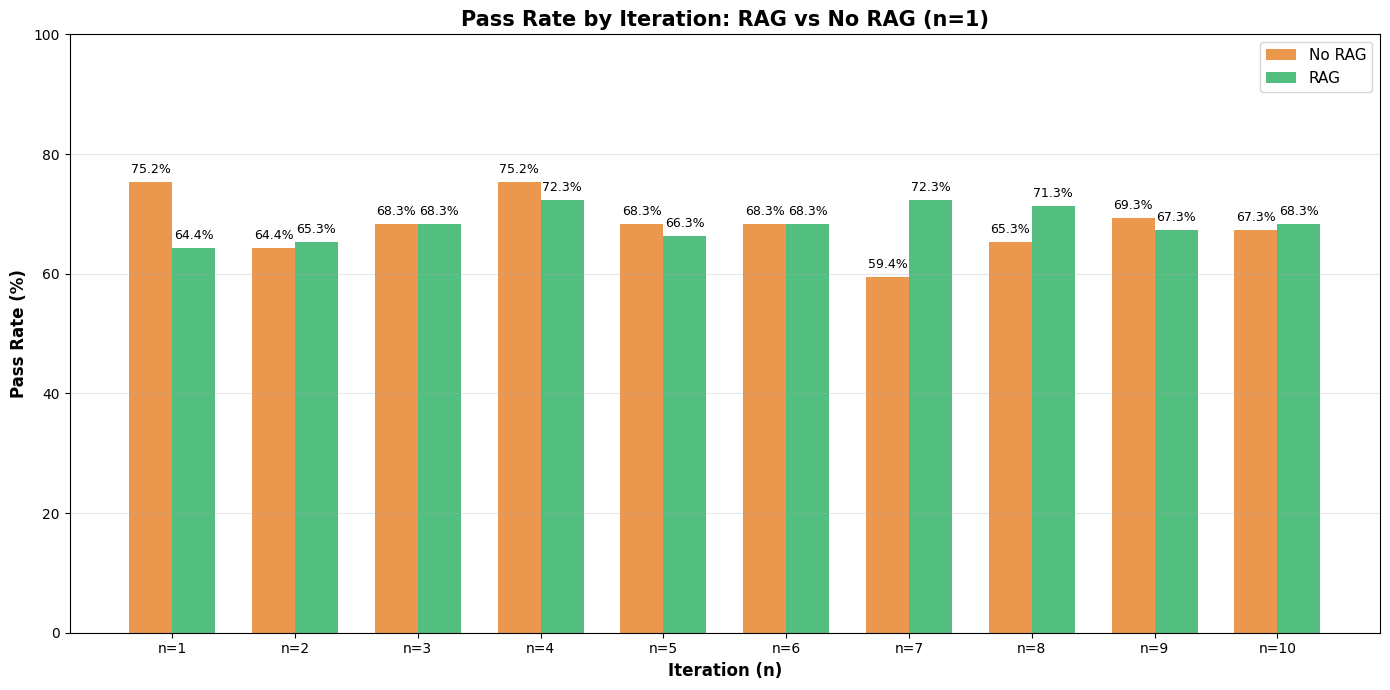

Detailed Pass Rate Comparison (RAG vs No RAG)
   iteration  attempts  pass_rate_no_rag  pass_rate_rag  difference
0          1         1         75.247525      64.356436  -10.891089
1          2         1         64.356436      65.346535    0.990099
2          3         1         68.316832      68.316832    0.000000
3          4         1         75.247525      72.277228   -2.970297
4          5         1         68.316832      66.336634   -1.980198
5          6         1         68.316832      68.316832    0.000000
6          7         1         59.405941      72.277228   12.871287
7          8         1         65.346535      71.287129    5.940594
8          9         1         69.306931      67.326733   -1.980198
9         10         1         67.326733      68.316832    0.990099

AVERAGE STATISTICS

Overall Average Pass Rate:
  No RAG: 68.12%
  RAG:    68.42%
  Difference: +0.30% (RAG better)

Average Pass Rate by Feedback Iteration (n = 'attempts' column):

  n |   No RAG |      R

In [91]:
# Filter for n=1 (attempts=1) across all iterations
rag_n1 = rag_df[rag_df['attempts'] == 1]
no_rag_n1 = no_rag_df[no_rag_df['attempts'] == 1]

# Calculate pass rates by iteration
rag_stats = calculate_pass_rate_by_iteration(rag_n1)
no_rag_stats = calculate_pass_rate_by_iteration(no_rag_n1)

# Print summary
print("RAG Pass Rates by Iteration:")
print(rag_stats)
print("\nNo RAG Pass Rates by Iteration:")
print(no_rag_stats)

# Create dictionaries for plotting
iterations = sorted(set(rag_stats['iteration'].tolist() + no_rag_stats['iteration'].tolist()))

# Ensure both datasets have all models (fill missing with 0)
rag_rates = {}
no_rag_rates = {}

for iteration in iterations:
    rag_row = rag_stats[rag_stats['iteration'] == iteration]
    no_rag_row = no_rag_stats[no_rag_stats['iteration'] == iteration]
    
    rag_rates[iteration] = rag_row['pass_rate'].values[0] if len(rag_row) > 0 else 0
    no_rag_rates[iteration] = no_rag_row['pass_rate'].values[0] if len(no_rag_row) > 0 else 0


fig = plot_iterations_bar_comparison(no_rag_rates, rag_rates, iterations)
plt.show()

# # Print detailed comparison
# print("\n" + "="*70)
# print("Iteration Comparison (Real Data, n=1):")
# print("="*70)
# for iteration in iterations:
#     no_rag_val = no_rag_rates[iteration]
#     rag_val = rag_rates[iteration]
#     diff = rag_val - no_rag_val
    
#     if diff > 0:
#         direction = f"✓ +{diff:.1f}%"
#         symbol = "↑"
#     elif diff < 0:
#         direction = f"✗ {diff:.1f}%"
#         symbol = "↓"
#     else:
#         direction = "→ No change"
#         symbol = "→"
    
#     print(f"Iteration {iteration:2d} {symbol} No RAG: {no_rag_val:5.1f}% | RAG: {rag_val:5.1f}% | {direction}")

detailed_comparison = calculate_average_rag_impact(rag_df, no_rag_df)
print("="*80)
print("Detailed Pass Rate Comparison (RAG vs No RAG)")
print("="*80)
print(detailed_comparison[['iteration', 'attempts', 'pass_rate_no_rag', 'pass_rate_rag', 'difference']])

# Calculate average statistics
print("\n" + "="*80)
print("AVERAGE STATISTICS")
print("="*80)

# Overall average across all (k, n) combinations
overall_avg_no_rag = detailed_comparison['pass_rate_no_rag'].mean()
overall_avg_rag = detailed_comparison['pass_rate_rag'].mean()
overall_avg_diff = detailed_comparison['difference'].mean()

print(f"\nOverall Average Pass Rate:")
print(f"  No RAG: {overall_avg_no_rag:.2f}%")
print(f"  RAG:    {overall_avg_rag:.2f}%")
print(f"  Difference: {overall_avg_diff:+.2f}% {'(RAG better)' if overall_avg_diff > 0 else '(No RAG better)'}")

# Average by attempt (n) - feedback iteration
print(f"\n{'='*80}")
print("Average Pass Rate by Feedback Iteration (n = 'attempts' column):")
print(f"{'='*80}")
by_attempt = detailed_comparison.groupby('attempts').agg({
    'pass_rate_no_rag': 'mean',
    'pass_rate_rag': 'mean',
    'difference': 'mean'
}).reset_index()

print(f"\n{'n':>3} | {'No RAG':>8} | {'RAG':>8} | {'Diff':>8} | Impact")
print("-" * 50)
for _, row in by_attempt.iterrows():
    n = int(row['attempts'])
    no_rag = row['pass_rate_no_rag']
    rag = row['pass_rate_rag']
    diff = row['difference']
    impact = "RAG ↑" if diff > 0 else "No RAG ↑" if diff < 0 else "Tie"
    print(f"{n:3d} | {no_rag:7.2f}% | {rag:7.2f}% | {diff:+7.2f}% | {impact}")

# Average by iteration (k) - independent attempt
print(f"\n{'='*80}")
print("Average Pass Rate by Independent Attempt (k = 'iteration' column):")
print(f"{'='*80}")
by_iteration = detailed_comparison.groupby('iteration').agg({
    'pass_rate_no_rag': 'mean',
    'pass_rate_rag': 'mean',
    'difference': 'mean'
}).reset_index()

print(f"\n{'k':>3} | {'No RAG':>8} | {'RAG':>8} | {'Diff':>8} | Impact")
print("-" * 50)
for _, row in by_iteration.iterrows():
    k = int(row['iteration'])
    no_rag = row['pass_rate_no_rag']
    rag = row['pass_rate_rag']
    diff = row['difference']
    impact = "RAG ↑" if diff > 0 else "No RAG ↑" if diff < 0 else "Tie"
    print(f"{k:3d} | {no_rag:7.2f}% | {rag:7.2f}% | {diff:+7.2f}% | {impact}")

# Summary statistics
print(f"\n{'='*80}")
print("SUMMARY STATISTICS:")
print(f"{'='*80}")
print(f"RAG improves pass rate in: {(detailed_comparison['difference'] > 0).sum()} / {len(detailed_comparison)} cases")
print(f"RAG worsens pass rate in:  {(detailed_comparison['difference'] < 0).sum()} / {len(detailed_comparison)} cases")
print(f"No change:                 {(detailed_comparison['difference'] == 0).sum()} / {len(detailed_comparison)} cases")
print(f"\nMaximum RAG improvement: +{detailed_comparison['difference'].max():.2f}%")
print(f"Maximum RAG degradation: {detailed_comparison['difference'].min():.2f}%")
print(f"Standard deviation of difference: {detailed_comparison['difference'].std():.2f}%")

# Statistical significance (if you want)
print(f"\n{'='*80}")
print("Does RAG make a statistically significant difference?")
print(f"{'='*80}")
from scipy import stats
t_stat, p_value = stats.ttest_rel(detailed_comparison['pass_rate_rag'], 
                                    detailed_comparison['pass_rate_no_rag'])
print(f"Paired t-test: t={t_stat:.3f}, p={p_value:.4f}")
if p_value < 0.05:
    print(f"Result: Statistically significant (p < 0.05)")
    if overall_avg_diff > 0:
        print("Conclusion: RAG significantly improves pass rates")
    else:
        print("Conclusion: RAG significantly worsens pass rates")
else:
    print(f"Result: Not statistically significant (p >= 0.05)")
    print("Conclusion: RAG does not significantly affect pass rates")


In [92]:
def get_passing_kernels(df, iteration):
    """
    Return set of kernel names that passed ('match' == 'match') for a given iteration.
    """
    return set(df[(df['iteration'] == iteration) & (df['match'] == 'match')]['kernel'])


In [93]:
def get_latency_for_kernels(df, iteration, kernels):
    """
    Return latency values for a given iteration and set of kernels,
    skipping missing, zero, or invalid entries (like '-' or 0).
    """
    # Select relevant rows
    subset = df[
        (df['iteration'] == iteration) &
        (df['kernel'].isin(kernels)) &
        (df['match'] == 'match')
    ]
    # Filter out rows where latency is '-' or 0 or missing
    valid_latencies = subset[
        subset['latency'].apply(lambda x: x not in ['-', 0, '0'] and pd.notnull(x))
    ]
    # Convert to float and filter out any zeros that slipped through
    latencies = valid_latencies['latency'].astype(float)
    latencies = latencies[latencies != 0]
    return latencies.values

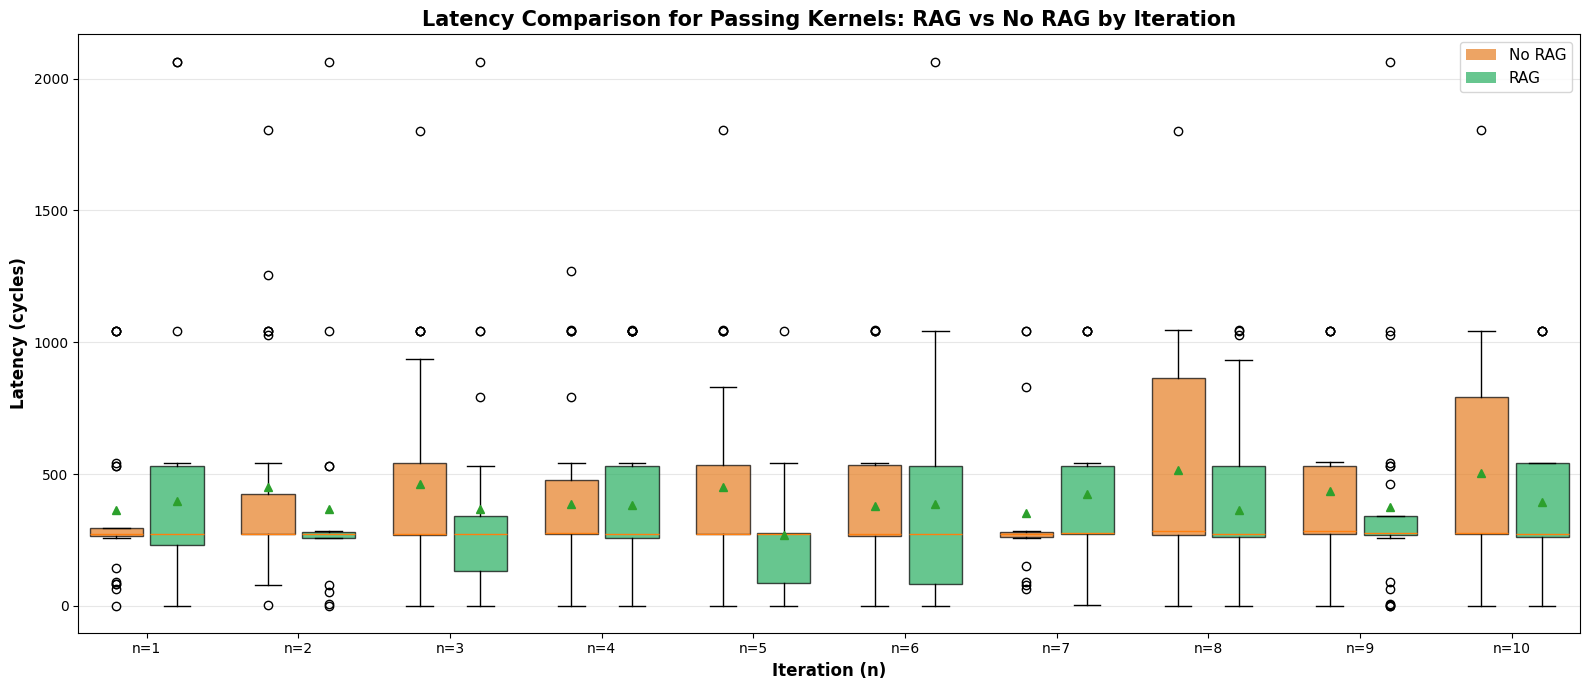

 Iter |   Mean RAG | Mean NoRAG |     Diff |  t p-val | Wilc p-val |   N
----------------------------------------------------------------------
Paired t-test p-value: 0.3576
Result: No statistically significant difference in mean latency (t-test)
Wilcoxon signed-rank p-value: 0.0377
Result: Statistically significant difference in median latency (Wilcoxon)

Overall Latency Comparison (All Iterations):
Mean RAG: 363.70, Mean No RAG: 388.00, Diff: -24.30
Paired t-test p-value: 0.3576
Wilcoxon signed-rank p-value: 0.0377


In [ ]:
# Get all iterations present in both datasets
iterations = sorted(set(rag_df['iteration']).intersection(set(no_rag_df['iteration'])))

rag_latencies = []
no_rag_latencies = []
labels = []

for iteration in iterations:
    # Find kernels that passed in BOTH RAG and NO RAG for this iteration
    rag_passed = get_passing_kernels(rag_df, iteration)
    no_rag_passed = get_passing_kernels(no_rag_df, iteration)
    common_passed = rag_passed & no_rag_passed
    
    # Get latency values for these kernels
    rag_lat = get_latency_for_kernels(rag_df, iteration, common_passed)
    no_rag_lat = get_latency_for_kernels(no_rag_df, iteration, common_passed)
    
    rag_latencies.append(rag_lat)
    no_rag_latencies.append(no_rag_lat)
    labels.append(f'n={iteration}')

# Prepare data for grouped boxplot
data = []
positions = []
group_labels = []

for i, label in enumerate(labels):
    data.append(no_rag_latencies[i])
    positions.append(i * 2 - 0.4)
    group_labels.append(f'{label}\nNo RAG')
    
    data.append(rag_latencies[i])
    positions.append(i * 2 + 0.4)
    group_labels.append(f'{label}\nRAG')

# Plot grouped boxplot
fig, ax = plt.subplots(figsize=(16, 7))

bp = ax.boxplot(data, positions=positions, widths=0.7, patch_artist=True, showmeans=True, medianprops={'color': 'red'})

# Color boxes
for i, box in enumerate(bp['boxes']):
    color = '#E67E22' if i % 2 == 0 else '#27AE60'
    box.set(facecolor=color, alpha=0.7)

# Set x-ticks and labels
ax.set_xticks([i * 2 for i in range(len(labels))])
ax.set_xticklabels(labels)
ax.set_xlabel('Iteration (n)', fontsize=12, fontweight='bold')
ax.set_ylabel('Latency (cycles)', fontsize=12, fontweight='bold')
ax.set_title('Latency Comparison for Passing Kernels: RAG vs No RAG by Iteration', fontsize=15, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#E67E22', alpha=0.7, label='No RAG'),
                   Patch(facecolor='#27AE60', alpha=0.7, label='RAG')]
ax.legend(handles=legend_elements, fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

# For each iteration, get latency arrays for kernels that passed in both conditions
iteration_stats = []

for i, iteration in enumerate(iterations):
    rag_lat = rag_latencies[i]
    no_rag_lat = no_rag_latencies[i]
    
    # Only compare if there are enough paired samples
    if len(rag_lat) > 1 and len(no_rag_lat) > 1 and len(rag_lat) == len(no_rag_lat):
        # Paired t-test (assumes normality of differences)
        t_stat, p_value = stats.ttest_rel(rag_lat, no_rag_lat)
        
        # Non-parametric alternative (Wilcoxon signed-rank test)
        try:
            w_stat, w_p_value = stats.wilcoxon(rag_lat, no_rag_lat)
        except ValueError:
            w_stat, w_p_value = np.nan, np.nan
        
        mean_rag = np.mean(rag_lat)
        mean_no_rag = np.mean(no_rag_lat)
        mean_diff = mean_rag - mean_no_rag
        
        iteration_stats.append({
            'iteration': iteration,
            'mean_rag': mean_rag,
            'mean_no_rag': mean_no_rag,
            'mean_diff': mean_diff,
            't_stat': t_stat,
            't_p_value': p_value,
            'wilcoxon_stat': w_stat,
            'wilcoxon_p_value': w_p_value,
            'n': len(rag_lat)
        })

# Print summary
print(f"{'Iter':>5} | {'Mean RAG':>10} | {'Mean NoRAG':>10} | {'Diff':>8} | {'t p-val':>8} | {'Wilc p-val':>10} | {'N':>3}")
print("-" * 70)
for stat in iteration_stats:
    print(f"{stat['iteration']:>5} | {stat['mean_rag']:10.2f} | {stat['mean_no_rag']:10.2f} | {stat['mean_diff']:8.2f} | {stat['t_p_value']:8.4f} | {stat['wilcoxon_p_value']:10.4f} | {stat['n']:>3}")

rag_latencies = []
no_rag_latencies = []
iterations = sorted(set(rag_df['iteration']).intersection(set(no_rag_df['iteration'])))

for iteration in iterations:
    # Find common passing kernels
    rag_passed = set(rag_df[(rag_df['iteration'] == iteration) & (rag_df['match'] == 'match')]['kernel'])
    no_rag_passed = set(no_rag_df[(no_rag_df['iteration'] == iteration) & (no_rag_df['match'] == 'match')]['kernel'])
    common_passed = rag_passed & no_rag_passed

    rag_lat = []
    no_rag_lat = []
    for kernel in common_passed:
        # Get latency for this kernel in both RAG and No RAG, skip if missing, '-', or 0
        rag_row = rag_df[(rag_df['iteration'] == iteration) & (rag_df['kernel'] == kernel) & (rag_df['match'] == 'match')]
        no_rag_row = no_rag_df[(no_rag_df['iteration'] == iteration) & (no_rag_df['kernel'] == kernel) & (no_rag_df['match'] == 'match')]
        if not rag_row.empty and not no_rag_row.empty:
            rag_latency = rag_row.iloc[0]['latency']
            no_rag_latency = no_rag_row.iloc[0]['latency']
            # Exclude '-', '0', or 0
            if rag_latency not in ['-', '0', 0] and no_rag_latency not in ['-', '0', 0]:
                rag_latency = float(rag_latency)
                no_rag_latency = float(no_rag_latency)
                if rag_latency != 0 and no_rag_latency != 0:
                    rag_lat.append(rag_latency)
                    no_rag_lat.append(no_rag_latency)
    rag_latencies.append(np.array(rag_lat))
    no_rag_latencies.append(np.array(no_rag_lat))

# Now you can safely concatenate
all_rag = np.concatenate([arr for arr in rag_latencies if len(arr) > 0])
all_no_rag = np.concatenate([arr for arr in no_rag_latencies if len(arr) > 0])


if len(all_rag) > 1 and len(all_no_rag) > 1 and len(all_rag) == len(all_no_rag):
    t_stat, t_p_value = stats.ttest_rel(all_rag, all_no_rag)

    # Wilcoxon signed-rank test (non-parametric)
    w_stat, w_p_value = stats.wilcoxon(all_rag, all_no_rag)

    print(f"Paired t-test p-value: {t_p_value:.4f}")
    if t_p_value < 0.05:
        print("Result: Statistically significant difference in mean latency (t-test)")
    else:
        print("Result: No statistically significant difference in mean latency (t-test)")

    print(f"Wilcoxon signed-rank p-value: {w_p_value:.4f}")
    if w_p_value < 0.05:
        print("Result: Statistically significant difference in median latency (Wilcoxon)")
    else:
        print("Result: No statistically significant difference in median latency (Wilcoxon)")


    # t_stat, p_value = stats.ttest_rel(all_rag, all_no_rag)
    # try:
    #     w_stat, w_p_value = stats.wilcoxon(all_rag, all_no_rag)
    # except ValueError:
    #     w_stat, w_p_value = np.nan, np.nan
    print("\nOverall Latency Comparison (All Iterations):")
    print(f"Mean RAG: {np.mean(all_rag):.2f}, Mean No RAG: {np.mean(all_no_rag):.2f}, Diff: {np.mean(all_rag) - np.mean(all_no_rag):.2f}")
    print(f"Paired t-test p-value: {p_value:.4f}")
    print(f"Wilcoxon signed-rank p-value: {w_p_value:.4f}")
else:
    print("\nNot enough paired data for overall test.")
